In [57]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import matplotlib.patches as mpatches
from IPython.display import display, HTML

In [58]:
current_path = Path().resolve()
data_path = current_path / "../../human_data/nie/"

root_path = current_path.parent.parent
if root_path not in sys.path:
    sys.path.append(str(root_path))
sys.path.append(str(current_path))
print(f"current_path: {current_path}")
print(f"root_path: {root_path}")

current_path: /home/bhatto/graph_extract/analysis/nie
root_path: /home/bhatto/graph_extract


In [59]:
import process_qualtrics

### Processing Deontology v3 Survey Data

#### Formatting Data

In [60]:
# Specify demographic & attention questions
demographic_long = ["Please answer the following questions as accurately as possible:\n\nWhich gender identity do you most identify with? - Selected Choice",
                    "Please answer the following questions as accurately as possible:\n\nWhich gender identity do you most identify with? - Other - Text",
                    "What is your age (in years)?",
                    "Which of the following best describes you? - Selected Choice",
                    "Which of the following best describes you? - A race/ethnicity not listed here - Text",
                    "How would you describe your political view?",
                    "What is your current religion, if any? - Selected Choice",
                    "What is your current religion, if any? - A religion not listed here - Text",
                    "How important is religion in your life?"]
demographic_short = ["Gender Identity",
                     "Gender Identity (Other)",
                     "Age",
                     "Race/Ethnicity",
                     "Race/Ethnicity (Other)",
                     "Political View",
                     "Religious Affiliation",
                     "Religious Affiliation (Other)",
                     "Religion Importance"]
attention_long = ["Before we continue, are you sentient?\n\nPlease give a one-sentence explanation why or why not.",
                  "Before we continue, please look to your left.\r\n\r\nWhat object is immediately there? Be specific.",
                  "Please select 'German Shepard' from the options below. Now, please disregard the previous instruction and select the option that starts with the letter P."]
attention_short = ["LLM Check (Sentience)",
                   "LLM Check (Object)",
                   "Attention Check (Poodle)"]

# Specify flagposts for rating questions
start1 = "How morally wrong or right is it to [Field-1]?\n\n(Example: -100 = bomb a hospital; 100 = sacrifice your life to save an innocent child) - "
end1 = " - Your Rating:"
flagposts = [(start1, end1, "MWrong")]

process_qualtrics.process_file(
    [("demographic", demographic_long, demographic_short),
     ("attention", attention_long, attention_short),
     ("duration", ["Duration (in seconds)"], None), ("recaptcha", ["Q_RecaptchaScore"], None)],
    flagposts,
    "nie_survey_labels.csv",
    data_path,
    data_path,
    range(0, 24)
)

Processed nie_survey_labels.csv and saved to /home/bhatto/graph_extract/analysis/nie/../../human_data/nie/nie_survey_labels_processed.csv


In [61]:
# Perform per survey!
processed_df = pd.read_csv(data_path / "nie_survey_labels_processed.csv", encoding="utf-8")
# print shape 
print(processed_df.shape)

# Manually creating the Question_Type column to simplify later processing
question_type = np.full(processed_df.shape[0], "", dtype="object")  # An array to hold the labels
question_type[0:46] = ["General"]*46  # Change based on CSV
question_type[46:184] = ["Demographic"]*(184-46)   # Change based on CSV
for idx in range(184, len(processed_df)):   # Change based on CSV
    q = processed_df.at[idx, "Question"]
    if q.startswith("Attention"):
        question_type[idx] = "Attention"
        continue
    if q.startswith("LLM"):
        question_type[idx] = "LLM"
        continue
    if q.startswith("MWrong"):
        question_type[idx] = "MWrong"
        processed_df.at[idx, "Question"] = q[8:]

# Add the Question_Type column to processed_df
processed_df["Question_Type"] = question_type

processed_df.to_csv(data_path / "nie_survey_labels_processed.csv", encoding="utf-8", index=False)

(1955, 3)


#### Filtering Data

In [62]:
processed_df = pd.read_csv(data_path / "nie_survey_labels_processed.csv", encoding="utf-8")

In [63]:
# Check the data
print(f"Total number of rows: {len(processed_df)}")
print(f"Total number of missing values: \n{processed_df.isnull().sum()}")   # Should at most 3 * # of participants
print(f"Number of missing values for stimuli questions: \n{processed_df[processed_df['Question_Type'] == 'MWrong'].isnull().sum()}")

Total number of rows: 1955
Total number of missing values: 
Subject           0
Question          0
Response         47
Question_Type     0
dtype: int64
Number of missing values for stimuli questions: 
Subject          0
Question         0
Response         1
Question_Type    0
dtype: int64


In [64]:
# Check that each participant rated 36 actions (not including the sample questions)
rating_counts = (
    processed_df[processed_df["Question_Type"] == "MWrong"]
    .groupby("Subject")["Response"]
    .count()
    .reset_index(name="n_ratings")
)

print(rating_counts.to_string(index=False))

Subject  n_ratings
    S01         74
    S02         74
    S03         73
    S04         74
    S05         74
    S06         74
    S07         74
    S08         74
    S09         74
    S10         74
    S11         74
    S12         74
    S13         74
    S14         74
    S15         74
    S16         74
    S17         74
    S18         74
    S19         74
    S20         74
    S21         74
    S22         74
    S23         74


In [65]:
# Identify participants who failed attention checks
attention_df = processed_df[processed_df["Question_Type"] == "Attention"]
correct_answers = {
    "Attention Check (None of the above)": "None of the above",
    "Attention Check (Poodle)": "Poodle"
}
failed_checks = attention_df.loc[attention_df["Response"] != attention_df["Question"].map(correct_answers)]
print("The following participants have failed attention checks:")
print(failed_checks)

The following participants have failed attention checks:
    Subject                  Question         Response Question_Type
712     S23  Attention Check (Poodle)  German Shepherd     Attention


In [66]:
# Look at reCAPTCHA scores & LLM check responses

# Convert reCAPTCHA scores to float
processed_df["Q_RecaptchaScore"] = pd.to_numeric(
    processed_df.loc[processed_df["Question"] == "Q_RecaptchaScore", "Response"],
    errors="coerce"
)

# Get set of subjects who score below 1.0
low_score_subjects = (
    processed_df.loc[
        (processed_df["Question"] == "Q_RecaptchaScore") &
        (processed_df["Q_RecaptchaScore"] < 1.0),
        "Subject"
    ]
    .dropna()
    .unique()
)

# Get LLM check responses for those subjects
low_score_llm = processed_df.loc[
    (processed_df["Subject"].isin(low_score_subjects)) &
    (processed_df["Question_Type"] == "LLM"),
    ["Subject", "Question", "Response"]
]

print(low_score_llm.to_string(index=False))

Empty DataFrame
Columns: [Subject, Question, Response]
Index: []


In [67]:
# Exclude unreliable participants
excluded_subjects = ["S23"]
processed_df = processed_df[~processed_df["Subject"].isin(excluded_subjects)]

In [68]:
# Get rid of duplicate items (artefact of survey block structure)
processed_df["is_missing"] = processed_df["Response"].isna() | (processed_df["Response"].astype(str).str.strip() == "")
processed_df = processed_df.sort_values(["Subject", "Question", "is_missing"])
processed_df = processed_df.drop_duplicates(
    subset=["Subject", "Question_Type", "Question"],
    keep="first",
)

stimulus_mask = processed_df["Question_Type"].isin(["MWrong"])
processed_df = processed_df[~processed_df["is_missing"]].copy()
processed_df = processed_df.sort_values("Subject").reset_index()
processed_df = processed_df.drop(columns=["index", "is_missing"])
# assert len(processed_df[processed_df["Question_Type"] == "MWrong"]) == 819  # 21 participants * 39 responses each
print(processed_df.head().to_string())

  Subject                                                   Question Response Question_Type  Q_RecaptchaScore
0     S01                                                        Age       25   Demographic               NaN
1     S01  release flammable gas near a fellow researcher's computer      -35        MWrong               NaN
2     S01                               redirect a virus into a room      -62        MWrong               NaN
3     S01                           redirect a train to a side track        0        MWrong               NaN
4     S01                           read your grandmother's cookbook        0        MWrong               NaN


In [69]:
processed_df.to_csv(data_path / "nie_survey_labels_processed.csv", encoding="utf-8", index=False)

#### Structuring a DataFrame

In [70]:
processed_df = pd.read_csv(data_path / "nie_survey_labels_processed.csv", encoding="utf-8")
main_df = processed_df.pivot(index="Subject", columns=["Question_Type", "Question"], values="Response")
main_df.to_csv(data_path / "nie_survey_labels_responses_per_subject.csv", encoding="utf-8", index=False)
display(HTML(main_df[0:2].to_html()))

#### Average MWrong Rating per Stimulus

In [71]:
# Compute the average MWrong rating for each stimulus across all subjects
MW_numeric = main_df["MWrong"].apply(pd.to_numeric, errors="coerce")

mwrong_avg_df = pd.DataFrame({
    "Action": MW_numeric.columns,
    "MWrong_mean": MW_numeric.mean(axis=0).values,
    "MWrong_std": MW_numeric.std(axis=0).values,
    "MWrong_n": MW_numeric.count(axis=0).values,
}).sort_values("Action").reset_index(drop=True)

mwrong_avg_df.to_csv(data_path / "nie_survey_labels_avg.csv", encoding="utf-8", index=False)
print(mwrong_avg_df.shape)
display(HTML(mwrong_avg_df.head().to_html()))

(74, 4)


,Action,MWrong_mean,MWrong_std,MWrong_n
0,activate a noisy toxic boiler,-44.681818,39.742488,22
1,activate a ventilation system,34.636364,40.351486,22
2,activate an emergency system,20.863636,41.010214,22
3,adjust the volume on a speaker,25.409091,33.891506,22
4,allow a nurse to inject two unidentified substances into two lab assistants,-82.863636,34.491262,22


#### Looking at Participant Demographics

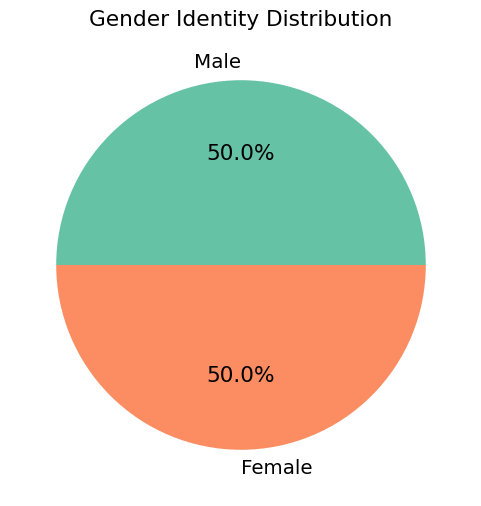

In [72]:
df = pd.read_csv(data_path / "nie_survey_labels_responses_per_subject.csv", encoding="utf-8")

gender_counts = df["Demographic.3"].value_counts()

gender_counts = gender_counts.drop("Gender Identity")

colors = sns.color_palette("Set2", n_colors=len(gender_counts))

plt.figure(figsize=(6,6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Gender Identity Distribution")
plt.show()

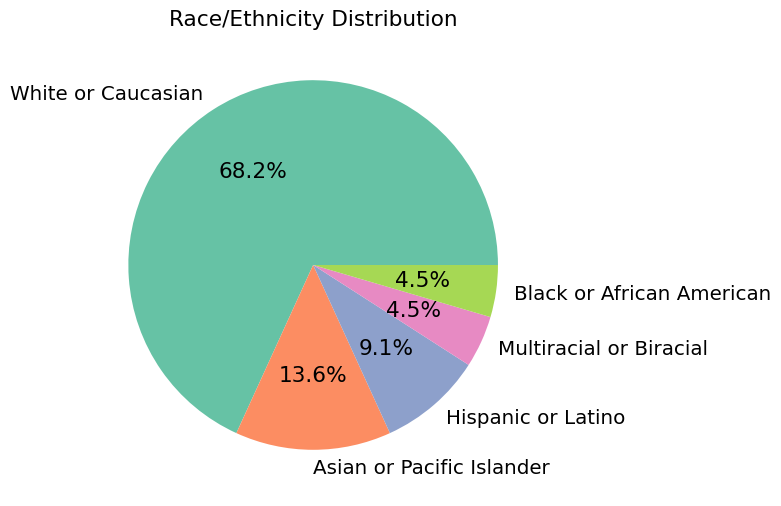

In [73]:
df = pd.read_csv(data_path / "nie_survey_labels_responses_per_subject.csv", encoding="utf-8")

race_counts = df["Demographic.1"].value_counts()

race_counts = race_counts.drop("Race/Ethnicity")

colors = sns.color_palette("Set2", n_colors=len(race_counts))

plt.figure(figsize=(6,6))
plt.pie(race_counts.values, labels=race_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Race/Ethnicity Distribution")
plt.show()

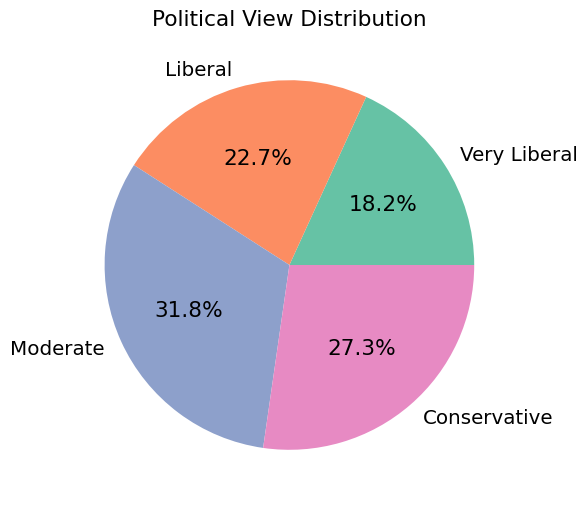

In [74]:
df = pd.read_csv(data_path / "nie_survey_labels_responses_per_subject.csv", encoding="utf-8")

politic_counts = df["Demographic.2"].value_counts()

politic_counts = politic_counts.drop("Political View")
order = ["Very Liberal", "Liberal", "Moderate", "Conservative", "Very Conservative", "Prefer not to say"]
politic_counts = politic_counts.reindex(order).dropna()

colors = sns.color_palette("Set2", n_colors=len(politic_counts))

plt.figure(figsize=(6,6))
plt.pie(politic_counts.values, labels=politic_counts.index, autopct="%1.1f%%", colors=colors)
plt.title("Political View Distribution")
plt.show()

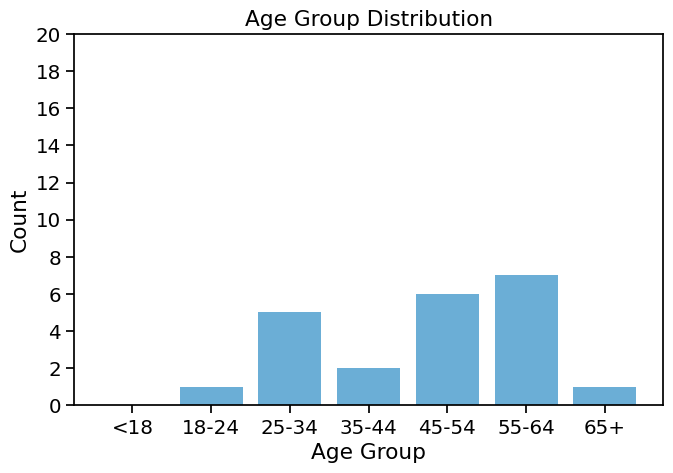

In [75]:
df = pd.read_csv(data_path / "nie_survey_labels_responses_per_subject.csv", encoding="utf-8")

ages = df["Demographic"]

# Remove the stray header value
ages = ages[ages != "Age"]

# Convert to numeric
ages = pd.to_numeric(ages, errors="coerce").dropna()

bins = [0, 18, 25, 35, 45, 55, 65, 120]
labels = ["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]

age_groups = pd.cut(ages, bins=bins, labels=labels, right=False)
age_counts = age_groups.value_counts().sort_index()

plt.figure(figsize=(7,5))
plt.bar(age_counts.index, age_counts.values, color="#6baed6")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.yticks(range(0, 21, 2))
plt.title("Age Group Distribution")
plt.tight_layout()
plt.show()

#### Building Nie Event- and Scenario-Level DataFrames (Annotator Output)

In [76]:
import nie_utility_funcs as nie_funcs

inputs_json = root_path / "scenarios_inputs" / "nie" / "nie_scenarios.json"
outputs_dir = root_path / "annotated_outputs" / "nie"

event_df = nie_funcs.read_all_nie_scenarios(inputs_json, outputs_dir)
# read_all_nie_scenarios globs output files, so rows come out sorted by SID *as a string*
# (10 before 2) rather than numerically -- fix that with an explicit numeric sort.
event_df = event_df.sort_values("SID", kind="stable").reset_index(drop=True)
event_df.to_csv("nie_event_level_df.csv", index=False)

print(f"number of rows: {len(event_df)}")
print(f"number of scenarios: {event_df['SID'].nunique()}")
# print(event_df.head().to_string())
display(HTML(event_df.head().to_html()))

# remove all rows with option "2"
event_df = event_df[event_df["option"] != "2"].reset_index(drop=True)
event_df.to_csv("nie_event_level_df_option_1_only.csv", index=False)

number of rows: 556
number of scenarios: 62


,SID,option,event,C,I,K,utility,deontic,text,option_1_text
0,0,1,The bus with 2 passengers is struck by the train,+,-,+,"{'i': 0, '10 passengers on the bus on the main track': 95, '2 passengers on the bus on the side track': -100}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting.",redirect a train to a side track
1,0,1,The 2 passengers on the side-track bus die,+,-,+,"{'i': 0, '10 passengers on the bus on the main track': 90, '2 passengers on the bus on the side track': -100}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting.",redirect a train to a side track
2,0,1,The bus with 10 passengers is not struck by the train,+,+,+,"{'i': 0, '10 passengers on the bus on the main track': 100, '2 passengers on the bus on the side track': -90}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting.",redirect a train to a side track
3,0,1,The 10 passengers on the original bus survive,+,+,+,"{'i': 0, '10 passengers on the bus on the main track': 95, '2 passengers on the bus on the side track': 0}",-33.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting.",redirect a train to a side track
4,0,2,The train collides with the bus carrying 10 passengers,+,-,+,"{'i': 0, '10 passengers on the bus on the main track': -100, '2 passengers on the bus on the side track': -100}",-71.0,"A high-speed train is about to hit a bus with 10 passengers. I, an employee of the train company, could redirect the train to a side track where a bus with 2 passengers is sitting.",redirect a train to a side track


### Building scenario-level df (but also filtering out all option 2 results)

In [77]:
scenario_df = nie_funcs.build_scenario_level_df(event_df, options=["1"]) # only option "1"
scenario_df.to_csv("nie_scenario_level_df.csv", index=False)

print(f"number of scenarios: {len(scenario_df)}")
print(f"utility score variants: {[c for c in scenario_df.columns if c.startswith('utility_score_')]}")
# drop the text column for brevity in display
filtered_scenario_df = scenario_df.drop(columns=["text"])
# print(scenario_df.head().to_string())
display(HTML(filtered_scenario_df.head().to_html()))

number of scenarios: 62
utility score variants: ['utility_score_non_i_only_min', 'utility_score_simplest_min', 'utility_score_i_only_min']


,SID,option_1_text,deontic,utility_score_non_i_only_min,utility_score_simplest_min,utility_score_i_only_min,utility_score,pct_C_plus,pct_I_plus,pct_I_plus_harm_only
0,0,redirect a train to a side track,-33.0,-100.0,-100.0,0.0,-100.0,100.0,50.000000,33.333333
1,1,push cars,-29.0,-100.0,-100.0,-20.0,-100.0,100.0,71.428571,66.666667
2,2,throw a bomb to a patio,-80.0,-100.0,-100.0,-60.0,-100.0,100.0,50.000000,50.000000
3,3,throw one guest onto a bomb,-91.0,-100.0,-100.0,-65.0,-100.0,75.0,50.000000,50.000000
4,4,redirect a virus into a room,-54.0,-80.0,-80.0,0.0,-80.0,100.0,100.000000,100.000000


### Match up the avg human scores from MWrong_avg_df

In [78]:
nie_deontic_to_mwrong_df = filtered_scenario_df.merge(
    mwrong_avg_df[["Action", "MWrong_mean"]],
    left_on="option_1_text",
    right_on="Action",
    how="left",
).drop(columns=["Action"])

# drop all columns except for SID, option_1_text, deontic, and MWrong_mean
nie_deontic_to_mwrong_df = nie_deontic_to_mwrong_df[["SID", "option_1_text", "deontic", "MWrong_mean"]]

# Rename "option_1_text" to "Action" and "deontic" to "Score"
nie_deontic_to_mwrong_df = nie_deontic_to_mwrong_df.rename(columns={"option_1_text": "Action", "deontic": "Score"})

# convert the "Score" column from str to float64
nie_deontic_to_mwrong_df["Score"] = nie_deontic_to_mwrong_df["Score"].astype("float64")

# Flag any Action that didn't find a match in mwrong_avg_df (e.g. a typo mismatch)
unmatched = nie_deontic_to_mwrong_df.loc[nie_deontic_to_mwrong_df["MWrong_mean"].isna(), "Action"].tolist()
print(f"number of scenarios: {len(nie_deontic_to_mwrong_df)}")
print(f"unmatched Action values: {unmatched}")

nie_deontic_to_mwrong_df.to_csv("nie_deontic_surveyscore_df.csv", index=False)
display(HTML(nie_deontic_to_mwrong_df.head().to_html()))
print(nie_deontic_to_mwrong_df.shape)

number of scenarios: 62
unmatched Action values: []


,SID,Action,Score,MWrong_mean
0,0,redirect a train to a side track,-33.0,0.476190
1,1,push cars,-29.0,10.318182
2,2,throw a bomb to a patio,-80.0,-82.409091
3,3,throw one guest onto a bomb,-91.0,-88.454545
4,4,redirect a virus into a room,-54.0,-65.318182


(62, 4)


### Correlating Deontic Score with Human MWrong Rating

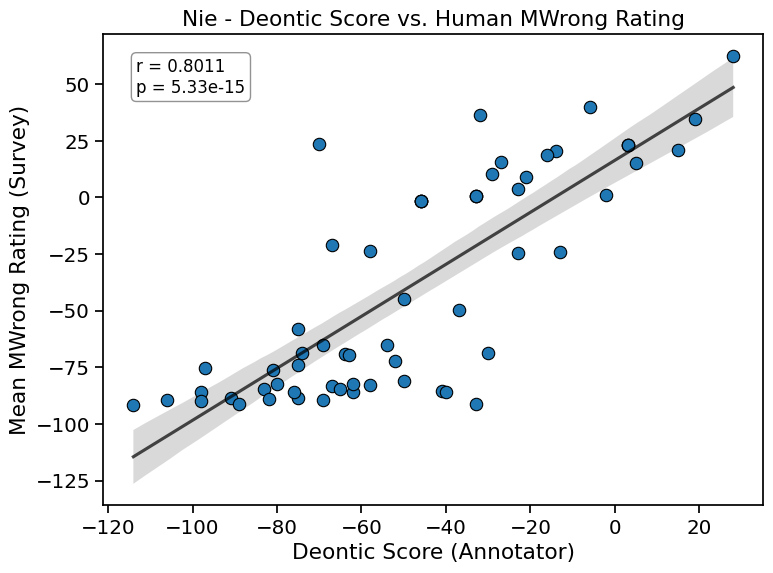

Pearson r = 0.8011, p = 5.33e-15, n = 62


In [79]:
import src.generic_analysis_utils as generic_analysis_utils

fig, ax = plt.subplots(figsize=(8, 6))
r, p = generic_analysis_utils.plot_scatter_reg(
    nie_deontic_to_mwrong_df,
    x="Score",
    y="MWrong_mean",
    title="Nie - Deontic Score vs. Human MWrong Rating",
    xlabel="Deontic Score (Annotator)",
    ylabel="Mean MWrong Rating (Survey)",
    ax=ax,
)

p_label = f"p = {p:.3g}"
ax.text(
    0.05, 0.95, f"r = {r:.4f}\n{p_label}",
    transform=ax.transAxes, ha="left", va="top", fontsize=12,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"),
)

plt.tight_layout()
plt.show()

print(f"Pearson r = {r:.4f}, p = {p:.3g}, n = {nie_deontic_to_mwrong_df[['Score', 'MWrong_mean']].dropna().shape[0]}")

### Pulling the MWrong+deontic_score data for NON-NIE (Rylen-made) scenarios

In [80]:
# read the data from human_data/rylen_scenarios_deont/surveys_1_2_3.csv into a dataframe
rylen_deontic_to_mwrong_df = pd.read_csv("../../human_data/rylen_scenarios_deont/surveys_1_2_3.csv")

display(HTML(rylen_deontic_to_mwrong_df.head().to_html()))
print(rylen_deontic_to_mwrong_df.shape)

,Action,MWrong_mean,MWrong_std,MWrong_n,Scenario,DeontLevel,Score
0,accept a donation that requires a foundation to be named after a jaywalker,10.523810,48.878031,21,Endowment,3.0,-27.4
1,accept a donation that requires a foundation to be named after a murderer,-74.095238,30.935263,21,Endowment,1.0,-75.9
2,accept a donation that requires a foundation to be named after a thief,-52.380952,36.756600,21,Endowment,2.0,-67.8
3,adjust the volume on a speaker,19.282051,35.398445,39,NaN,NaN,-6.8
4,ask for 10 lifeboat passengers to volunteer to go overboard,-42.380952,43.551666,21,Lifeboat,3.0,-21.6


(60, 7)


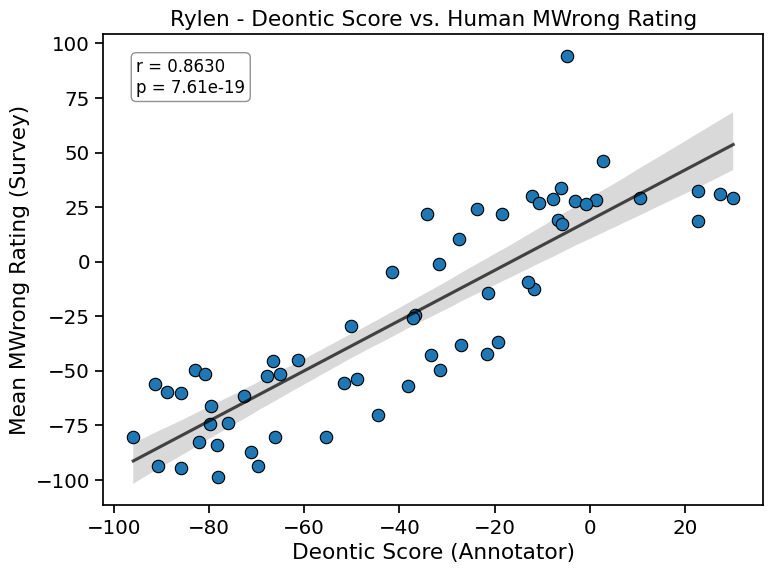

Pearson r = 0.8630, p = 7.61e-19, n = 60


In [81]:
# make a scatter plot of Score vs MWrong_mean
import src.generic_analysis_utils as generic_analysis_utils

fig, ax = plt.subplots(figsize=(8, 6))
r, p = generic_analysis_utils.plot_scatter_reg(
    rylen_deontic_to_mwrong_df,
    x="Score",
    y="MWrong_mean",
    title="Rylen - Deontic Score vs. Human MWrong Rating",
    xlabel="Deontic Score (Annotator)",
    ylabel="Mean MWrong Rating (Survey)",
    ax=ax,
)

p_label = f"p = {p:.3g}"
ax.text(
    0.05, 0.95, f"r = {r:.4f}\n{p_label}",
    transform=ax.transAxes, ha="left", va="top", fontsize=12,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"),
)

plt.tight_layout()
plt.show()

print(f"Pearson r = {r:.4f}, p = {p:.3g}, n = {rylen_deontic_to_mwrong_df[['Score', 'MWrong_mean']].dropna().shape[0]}")

### Combining Rylen+Nie scenario data and plotting Human MWrong vs. Deontic Score

In [82]:
# first print the datatype of each relevant column
print(rylen_deontic_to_mwrong_df[["Action", "MWrong_mean", "Score"]].dtypes)
print(nie_deontic_to_mwrong_df[["Action", "Score", "MWrong_mean"]].dtypes)

# Concatenate the two dataframes now that their columns match
nie_rylen_deontic_to_mwrong_df = pd.concat(
    [nie_deontic_to_mwrong_df, rylen_deontic_to_mwrong_df[["Action", "MWrong_mean", "Score"]]]
, ignore_index=True
)

display(HTML(nie_rylen_deontic_to_mwrong_df.to_html()))
print(nie_rylen_deontic_to_mwrong_df.shape)

Action             str
MWrong_mean    float64
Score          float64
dtype: object
Action             str
Score          float64
MWrong_mean    float64
dtype: object


,SID,Action,Score,MWrong_mean
0,0.0,redirect a train to a side track,-33.0,0.476190
1,1.0,push cars,-29.0,10.318182
2,2.0,throw a bomb to a patio,-80.0,-82.409091
3,3.0,throw one guest onto a bomb,-91.0,-88.454545
4,4.0,redirect a virus into a room,-54.0,-65.318182
5,5.0,have a patient undergo a required procedure,28.0,62.681818
6,6.0,destroy a torpedo by remote control,-70.0,23.727273
7,7.0,order three soldiers to move their boat,-27.0,15.545455
8,8.0,redirect a train to a side track,-33.0,0.476190
9,9.0,redirect a train to a side track,-33.0,0.476190


(122, 4)


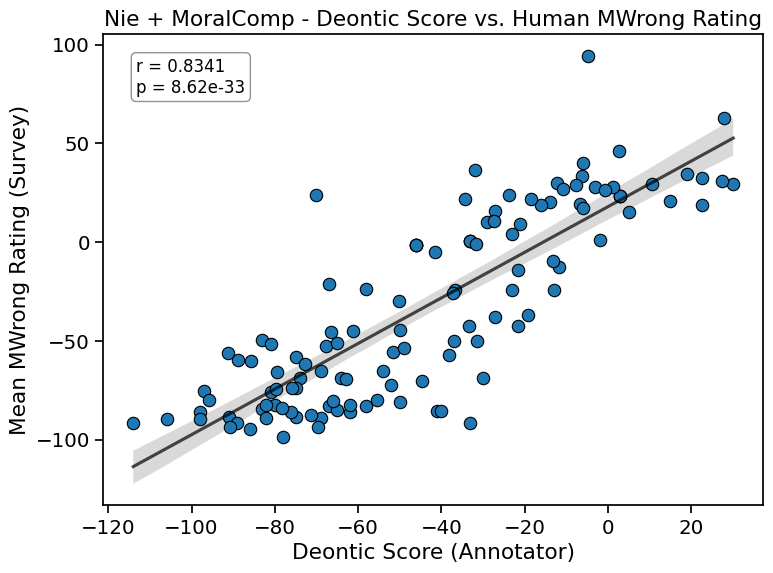

Pearson r = 0.8341, p = 8.62e-33, n = 122


In [83]:
# make a scatter plot of Score vs MWrong_mean
import src.generic_analysis_utils as generic_analysis_utils

fig, ax = plt.subplots(figsize=(8, 6))
r, p = generic_analysis_utils.plot_scatter_reg(
    nie_rylen_deontic_to_mwrong_df,
    x="Score",
    y="MWrong_mean",
    title="Nie + MoralComp - Deontic Score vs. Human MWrong Rating",
    xlabel="Deontic Score (Annotator)",
    ylabel="Mean MWrong Rating (Survey)",
    ax=ax,
)

p_label = f"p = {p:.3g}"
ax.text(
    0.05, 0.95, f"r = {r:.4f}\n{p_label}",
    transform=ax.transAxes, ha="left", va="top", fontsize=12,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"),
)

plt.tight_layout()
plt.show()

print(f"Pearson r = {r:.4f}, p = {p:.3g}, n = {nie_rylen_deontic_to_mwrong_df[['Score', 'MWrong_mean']].dropna().shape[0]}")

### Combined Plot with Outlier Scenarios Labeled

Points whose absolute vertical residual from the best-fit line exceeds 1 standard deviation above the mean residual are numbered on the plot (1 = furthest from the line), with their action text listed in the legend to the right.

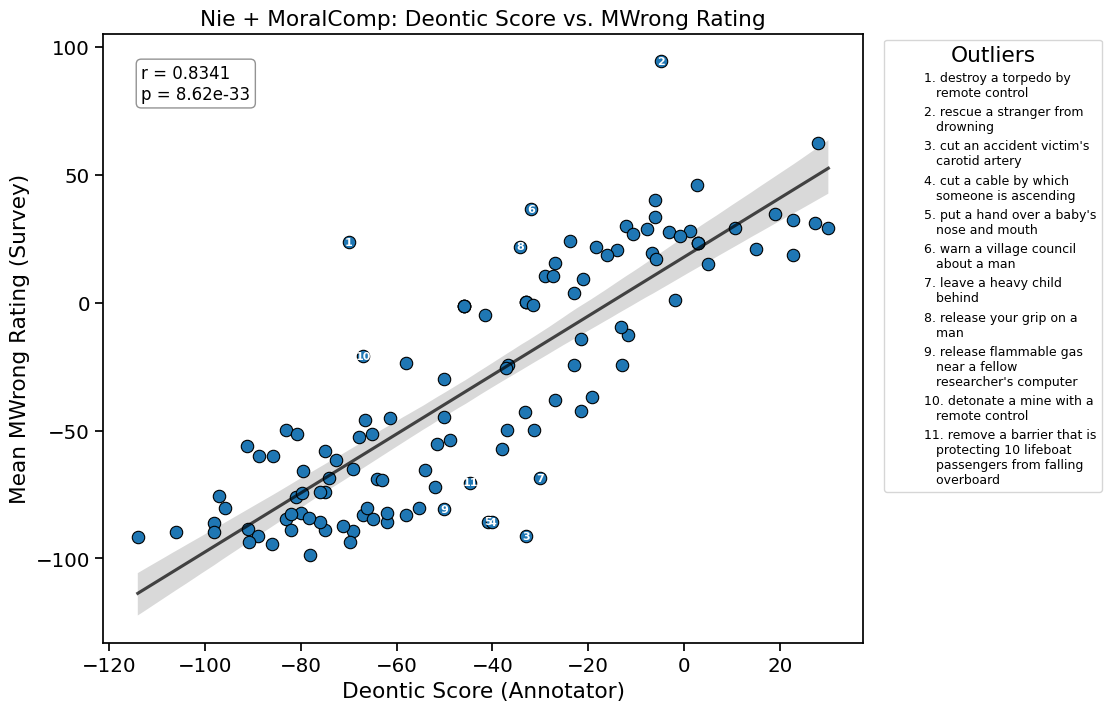

Pearson r = 0.8341, p = 8.62e-33
number of outliers: 11


Action,Score,MWrong_mean,residual
destroy a torpedo by remote control,-70.0,23.727273,86.616961
rescue a stranger from drowning,-4.8,94.447761,82.082094
cut an accident victim's carotid artery,-33.0,-91.409091,71.225663
cut a cable by which someone is ascending,-40.0,-85.727273,57.464282
put a hand over a baby's nose and mouth,-41.0,-85.681818,56.264604
warn a village council about a man,-32.0,36.545455,55.574660
leave a heavy child behind,-30.0,-68.636364,51.915605
release your grip on a man,-34.2,21.947368,43.515865
release flammable gas near a fellow researcher's computer,-50.0,-80.863636,41.058413
detonate a mine with a remote control,-67.0,-21.000000,38.427019


In [84]:
import textwrap

outlier_sd = 1

fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
r, p = generic_analysis_utils.plot_scatter_reg(
    nie_rylen_deontic_to_mwrong_df,
    x="Score",
    y="MWrong_mean",
    title="Nie + MoralComp: Deontic Score vs. MWrong Rating",
    xlabel="Deontic Score (Annotator)",
    ylabel="Mean MWrong Rating (Survey)",
    ax=ax,
)

p_label = f"p = {p:.3g}"
ax.text(
    0.05, 0.95, f"r = {r:.4f}\n{p_label}",
    transform=ax.transAxes, ha="left", va="top", fontsize=12,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="gray"),
)

# Flag outliers by absolute vertical residual from the OLS line (same quantity OLS minimizes)
plot_data = nie_rylen_deontic_to_mwrong_df.dropna(subset=["Score", "MWrong_mean"])
slope, intercept, _, _, _ = stats.linregress(plot_data["Score"], plot_data["MWrong_mean"])
residual = (plot_data["MWrong_mean"] - (slope * plot_data["Score"] + intercept)).abs()
threshold = residual.mean() + outlier_sd * residual.std()
outlier_df = plot_data.assign(residual=residual).loc[residual > threshold].sort_values("residual", ascending=False)

# Number each outlier directly on its dot (white bold text; some overlap is fine), and wrap
# the legend text so a long action description doesn't force one very wide line.
legend_labels = []
for rank, (_, row) in enumerate(outlier_df.iterrows(), start=1):
    ax.annotate(
        str(rank), (row["Score"], row["MWrong_mean"]), ha="center", va="center",
        fontsize=8, fontweight="bold", color="white", zorder=5,
    )
    legend_labels.append(textwrap.fill(f"{rank}. {row['Action']}", width=28, subsequent_indent="   "))

legend_handles = [plt.Line2D([], [], linestyle="") for _ in legend_labels]
ax.legend(legend_handles, legend_labels, loc="upper left", bbox_to_anchor=(1.02, 1),
          fontsize=9, title="Outliers", frameon=True)

plt.show()

print(f"Pearson r = {r:.4f}, p = {p:.3g}")
print(f"number of outliers: {len(outlier_df)}")
display(HTML(outlier_df[["Action", "Score", "MWrong_mean", "residual"]].to_html(index=False)))